# FedVocabHAR WISDM Phase 2A

## Representation redesign under open-world label restrictions

Phase 1C showed that admission and replay are safe, while activities I and L remain inseparable under the Phase Zero-B representation. Phase 2A tests whether a stronger subject-invariant temporal representation resolves that bottleneck before any further vocabulary-integration work.

Encoder selection uses only known-activity labels from development subjects. Integration-client streams may be used without activity labels for self-supervision. Evaluation-client activity labels are sealed until the selected encoder and all baselines are frozen.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
from collections import defaultdict
import copy,json,math,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,precision_recall_fscore_support,confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    encoder_train_subjects:tuple=tuple(range(1635,1640))
    encoder_selection_subjects:tuple=(1640,1641)
    unlabeled_integration_subjects:tuple=tuple(range(1643,1648))
    evaluation_subjects:tuple=tuple(range(1648,1651))
    known_activities:tuple=('F','G','H','I','K')
    novel_activities:tuple=('L','M','O','P','Q','S')
    embedding_dim:int=64
    labeled_per_subject_activity:int=180
    unlabeled_per_subject:int=900
    probe_per_class:int=300
    batch_size:int=128
    epochs:int=24
    learning_rate:float=1e-3
    weight_decay:float=1e-4
    supcon_weight:float=.20
    consistency_weight:float=.20
    reconstruction_weight:float=.35
    subject_adversary_weight:float=.10
    mask_fraction:float=.25
    known_accuracy_gate:float=.60
    known_i_f1_gate:float=.40
    oracle_novel_f1_gate:float=.70
    novel_l_f1_gate:float=.40

CFG=Config()
PROJECT=Path(CFG.project);P0=PROJECT/'artifacts'/'phase0';P0B=PROJECT/'artifacts'/'phase0b'
OUT=PROJECT/'artifacts'/'phase2a';OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz';BASELINE_MODEL=P0B/'contrastive_encoder.pt'
assert CACHE.exists() and BASELINE_MODEL.exists()
assert not (set(CFG.evaluation_subjects)&(set(CFG.encoder_train_subjects)|set(CFG.encoder_selection_subjects)|set(CFG.unlabeled_integration_subjects)))

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "encoder_train_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639
  ],
  "encoder_selection_subjects": [
    1640,
    1641
  ],
  "unlabeled_integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "embedding_dim": 64,
  "labeled_per_subject_activity": 180,
  "unlabeled_per_subject": 900,
  "probe_per_class": 300,
  "batch_size": 128,
  "epochs": 24,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "supcon_weight": 0.2,
  "consistency_weight": 0.2,
  "reconstruction_weight": 0.35,
  "subject_adversary_weight": 0.1,
  "mask_fraction": 0.25,
  "known_accuracy_gate": 0.6,
  "known_i_f1_gate": 0.4,
  "oracle_novel_f1_gate": 0.7,
  "novel_l_f1_gate": 0.4
}


## Load the fixed WISDM cache and Phase Zero-B baseline

All encoders receive the same watch-accelerometer windows and Phase Zero-B channel normalization. The existing contrastive CNN is evaluated unchanged as the baseline.


In [3]:
d=np.load(CACHE)
x=d['x'].astype(np.float32);subjects=d['subject'].astype(int)
activities=d['activity'].astype(str);positions=d['position'].astype(np.float32)

class BaselineEncoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,q):return F.normalize(self.project(self.body(q).squeeze(-1)),dim=1)

try:checkpoint=torch.load(BASELINE_MODEL,map_location='cpu',weights_only=False)
except TypeError:checkpoint=torch.load(BASELINE_MODEL,map_location='cpu')
channel_mean=np.asarray(checkpoint['channel_mean'],dtype=np.float32)
channel_std=np.asarray(checkpoint['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std
baseline=BaselineEncoder(int(checkpoint['config']['embedding_dim'])).to(DEVICE)
baseline.load_state_dict(checkpoint['state_dict']);baseline.eval()

def encode_batches(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):
            value=model(torch.from_numpy(data[start:start+batch]).to(DEVICE))
            if isinstance(value,tuple):value=value[0]
            out.append(value.cpu().numpy())
    return np.concatenate(out).astype(np.float32)

baseline_embeddings=encode_batches(baseline,xn)
print('windows:',x.shape,'baseline embeddings:',baseline_embeddings.shape)
print(pd.crosstab(subjects,activities).to_string())


windows: (19704, 3, 128) baseline embeddings: (19704, 96)
col_0    A    B    C    D    E    F    G    H    I    K    L    M    O    P    Q    R    S
row_0                                                                                     
1635    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1636    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1637   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1638   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1639   138  138  138  138  138  138  138  138  138  138    0  138  138  138  138  138  138
1640   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1641    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1643    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1644    55   55   55   55   55  

## Leakage-controlled training, selection, and evaluation partitions

- Encoder training labels: known activities from subjects 1635–1639.
- Encoder selection labels: known activities from subjects 1640–1641.
- Unlabeled self-supervision: subjects 1643–1647, without activity identities.
- Final evaluation: subjects 1648–1650, accessed only after encoder selection.

Novel labels from integration clients are used only for the final oracle linear-probe diagnostic; they never train or select an encoder.


In [4]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
all_activities=CFG.known_activities+CFG.novel_activities
all_to_index={a:i for i,a in enumerate(all_activities)}

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

train_idx=limited_by_group(CFG.encoder_train_subjects,CFG.known_activities,CFG.labeled_per_subject_activity,CFG.seed)
selection_idx=limited_by_group(CFG.encoder_selection_subjects,CFG.known_activities,CFG.labeled_per_subject_activity,CFG.seed+1)
unlabeled_idx=[];rng=np.random.default_rng(CFG.seed+2)
for subject in CFG.unlabeled_integration_subjects:
    idx=np.where(subjects==subject)[0]
    if len(idx)>CFG.unlabeled_per_subject:idx=rng.choice(idx,CFG.unlabeled_per_subject,replace=False)
    unlabeled_idx.extend(idx.tolist())
unlabeled_idx=np.asarray(unlabeled_idx,dtype=int)
eval_known_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities))[0]
eval_novel_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities))[0]

domain_subjects=CFG.encoder_train_subjects+CFG.unlabeled_integration_subjects
subject_to_domain={s:i for i,s in enumerate(domain_subjects)}
assert not set(subjects[train_idx])&set(CFG.evaluation_subjects)
assert not set(subjects[selection_idx])&set(CFG.evaluation_subjects)
assert not set(subjects[unlabeled_idx])&set(CFG.evaluation_subjects)
print('labeled train:',len(train_idx),'selection:',len(selection_idx),'unlabeled:',len(unlabeled_idx),
      'eval known/novel:',len(eval_known_idx),len(eval_novel_idx))


labeled train: 2620 selection: 965 unlabeled: 4500 eval known/novel: 825 995


## Temporal residual encoder and learning objectives

Three candidate encoders are trained:

1. **ResNet-CE:** known-class classification only.
2. **ResNet-CE-SupCon:** classification plus supervised contrastive learning.
3. **ResNet-Hybrid:** classification, supervised contrastive learning, masked reconstruction, temporal-view consistency, and gradient-reversal subject invariance using unlabeled integration streams.


In [5]:
class ResidualBlock(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__()
        self.conv1=nn.Conv1d(cin,cout,5,stride=stride,padding=2,bias=False);self.bn1=nn.BatchNorm1d(cout)
        self.conv2=nn.Conv1d(cout,cout,3,padding=1,bias=False);self.bn2=nn.BatchNorm1d(cout)
        self.skip=(nn.Identity() if cin==cout and stride==1 else
                   nn.Sequential(nn.Conv1d(cin,cout,1,stride=stride,bias=False),nn.BatchNorm1d(cout)))
    def forward(self,q):return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(q)))))+self.skip(q))

class GradientReverse(Function):
    @staticmethod
    def forward(ctx,q,lambd):ctx.lambd=lambd;return q.view_as(q)
    @staticmethod
    def backward(ctx,grad):return -ctx.lambd*grad,None

class TemporalResNet(nn.Module):
    def __init__(self,embedding_dim,n_known,n_domains,window_length):
        super().__init__()
        self.stem=nn.Sequential(nn.Conv1d(3,64,7,padding=3,bias=False),nn.BatchNorm1d(64),nn.ReLU())
        self.body=nn.Sequential(ResidualBlock(64,64),ResidualBlock(64,96,2),
                                ResidualBlock(96,128,2),ResidualBlock(128,128),nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,embedding_dim))
        self.classifier=nn.Linear(embedding_dim,n_known)
        self.decoder=nn.Sequential(nn.Linear(embedding_dim,256),nn.ReLU(),nn.Linear(256,3*window_length))
        self.domain=nn.Sequential(nn.Linear(embedding_dim,64),nn.ReLU(),nn.Linear(64,n_domains))
        self.window_length=window_length
    def features(self,q):
        h=self.body(self.stem(q)).squeeze(-1);return F.normalize(self.project(h),dim=1)
    def forward(self,q):
        f=self.features(q);return f,self.classifier(f)

def augment(q):
    scale=1+torch.randn(q.size(0),q.size(1),1,device=q.device)*.08
    noise=torch.randn_like(q)*.035
    shift=torch.randint(-4,5,(q.size(0),),device=q.device)
    out=q*scale+noise
    return torch.stack([torch.roll(out[i],int(shift[i].item()),dims=-1) for i in range(len(out))])

def mask_input(q):
    out=q.clone();length=max(1,int(q.size(-1)*CFG.mask_fraction))
    starts=torch.randint(0,q.size(-1)-length+1,(q.size(0),),device=q.device)
    for i,start in enumerate(starts):out[i,:,start:start+length]=0
    return out

def supcon_loss(z1,z2,y,temperature=.12):
    z=torch.cat([z1,z2],0);labels=torch.cat([y,y],0)
    logits=z@z.T/temperature
    eye=torch.eye(len(z),dtype=torch.bool,device=z.device)
    positives=labels[:,None].eq(labels[None,:])&~eye
    logits=logits-logits.max(1,keepdim=True).values.detach()
    exp=torch.exp(logits)*~eye;log_prob=logits-torch.log(exp.sum(1,keepdim=True)+1e-12)
    positive_count=positives.sum(1).clamp_min(1)
    return (-((log_prob*positives).sum(1)/positive_count)).mean()


## Train candidate encoders without evaluation labels

The best checkpoint for each candidate is selected by known-activity macro-F1 on development selection subjects. No evaluation-client data or novel-activity identity participates in checkpoint selection.


In [6]:
MODEL_NAMES=('phase0b_contrastive','resnet_ce','resnet_ce_supcon','resnet_hybrid')

def quick_known_probe(model):
    tr=encode_batches(model,xn[train_idx]);va=encode_batches(model,xn[selection_idx])
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=1200,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(tr,[known_to_index[a] for a in activities[train_idx]])
    pred=pipe.predict(va);true=np.asarray([known_to_index[a] for a in activities[selection_idx]])
    return float(f1_score(true,pred,average='macro'))

def train_candidate(name):
    seed_all(CFG.seed)
    model=TemporalResNet(CFG.embedding_dim,len(CFG.known_activities),len(domain_subjects),x.shape[-1]).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    rng=np.random.default_rng(CFG.seed);best=-1;best_state=None;history=[]
    for epoch in range(CFG.epochs):
        model.train();order=rng.permutation(train_idx);losses=[]
        for start in range(0,len(order),CFG.batch_size):
            li=order[start:start+CFG.batch_size]
            if len(li)<8:continue
            ui=rng.choice(unlabeled_idx,len(li),replace=len(unlabeled_idx)<len(li))
            xl=torch.from_numpy(xn[li]).to(DEVICE);yl=torch.tensor([known_to_index[a] for a in activities[li]],device=DEVICE)
            xu=torch.from_numpy(xn[ui]).to(DEVICE)
            opt.zero_grad();fl,logits=model(xl);loss=F.cross_entropy(logits,yl)
            if name in ('resnet_ce_supcon','resnet_hybrid'):
                z1=model.features(augment(xl));z2=model.features(augment(xl))
                loss=loss+CFG.supcon_weight*supcon_loss(z1,z2,yl)
            if name=='resnet_hybrid':
                u1=augment(xu);u2=augment(xu);fu1=model.features(u1);fu2=model.features(u2)
                consistency=(1-(fu1*fu2).sum(1)).mean()
                masked=mask_input(xu);fm=model.features(masked)
                reconstruction=F.mse_loss(model.decoder(fm).view_as(xu),xu)
                all_f=torch.cat([fl,fu1],0)
                domains=torch.tensor([subject_to_domain[int(s)] for s in np.concatenate([subjects[li],subjects[ui]])],device=DEVICE)
                domain_logits=model.domain(GradientReverse.apply(all_f,1.0))
                adversary=F.cross_entropy(domain_logits,domains)
                loss=loss+CFG.consistency_weight*consistency+CFG.reconstruction_weight*reconstruction+CFG.subject_adversary_weight*adversary
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.0);opt.step();losses.append(float(loss.detach().cpu()))
        score=quick_known_probe(model)
        history.append({'model':name,'epoch':epoch+1,'loss':float(np.mean(losses)),'selection_macro_f1':score})
        if score>best:best=score;best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(name,'epoch',epoch+1,'loss',round(float(np.mean(losses)),4),'selection F1',round(score,4))
    model.load_state_dict(best_state);model.eval()
    torch.save({'state_dict':best_state,'config':asdict(CFG),'model_name':name,
                'channel_mean':channel_mean,'channel_std':channel_std,'selection_macro_f1':best},OUT/f'{name}.pt')
    return model,history,best

trained={};history=[];selection_scores={}
for name in MODEL_NAMES[1:]:
    model,h,best=train_candidate(name);trained[name]=model;history.extend(h);selection_scores[name]=best
pd.DataFrame(history).to_csv(OUT/'phase2a_training_history.csv',index=False)


resnet_ce epoch 1 loss 1.3675 selection F1 0.2805
resnet_ce epoch 2 loss 1.1703 selection F1 0.2936
resnet_ce epoch 3 loss 1.0802 selection F1 0.252
resnet_ce epoch 4 loss 1.0029 selection F1 0.2507
resnet_ce epoch 5 loss 0.9652 selection F1 0.3427
resnet_ce epoch 6 loss 0.9037 selection F1 0.3154
resnet_ce epoch 7 loss 0.7801 selection F1 0.2815
resnet_ce epoch 8 loss 0.7435 selection F1 0.1158
resnet_ce epoch 9 loss 0.7191 selection F1 0.3071
resnet_ce epoch 10 loss 0.654 selection F1 0.2924
resnet_ce epoch 11 loss 0.6262 selection F1 0.2791
resnet_ce epoch 12 loss 0.6068 selection F1 0.2876
resnet_ce epoch 13 loss 0.5223 selection F1 0.3459
resnet_ce epoch 14 loss 0.51 selection F1 0.3236
resnet_ce epoch 15 loss 0.5085 selection F1 0.198
resnet_ce epoch 16 loss 0.4998 selection F1 0.3209
resnet_ce epoch 17 loss 0.4781 selection F1 0.313
resnet_ce epoch 18 loss 0.4624 selection F1 0.3466
resnet_ce epoch 19 loss 0.4419 selection F1 0.2955
resnet_ce epoch 20 loss 0.4225 selection F1 0.

## Development-only encoder selection

The Phase Zero-B baseline and all residual candidates are compared using a frozen linear probe on the development split. The encoder with the highest selection macro-F1 is frozen before final evaluation.


In [7]:
def ece_score(true,pred,confidence,bins=10):
    correct=(true==pred).astype(float);ece=0.0
    edges=np.linspace(0,1,bins+1)
    for lo,hi in zip(edges[:-1],edges[1:]):
        q=(confidence>lo)&(confidence<=hi)
        if q.any():ece+=q.mean()*abs(correct[q].mean()-confidence[q].mean())
    return float(ece)

def probe_metrics(train_e,train_y,test_e,test_y,labels):
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=2500,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(train_e,train_y);pred=pipe.predict(test_e);prob=pipe.predict_proba(test_e)
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return pipe,{'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(f1_score(test_y,pred,labels=labels,average='macro',zero_division=0)),
                 'ece':ece_score(test_y,pred,prob.max(1)),'pred':pred,'per_class_f1':f1s}

embeddings={'phase0b_contrastive':baseline_embeddings}
for name,model in trained.items():embeddings[name]=encode_batches(model,xn)

selection_rows=[]
train_y=np.asarray([known_to_index[a] for a in activities[train_idx]])
selection_y=np.asarray([known_to_index[a] for a in activities[selection_idx]])
for name,e in embeddings.items():
    _,m=probe_metrics(e[train_idx],train_y,e[selection_idx],selection_y,list(range(len(CFG.known_activities))))
    selection_rows.append({'model':name,'selection_accuracy':m['accuracy'],'selection_macro_f1':m['macro_f1'],'selection_ece':m['ece']})
selection=pd.DataFrame(selection_rows).sort_values(['selection_macro_f1','selection_ece'],ascending=[False,True])
SELECTED_ENCODER=str(selection.iloc[0].model)
selection.to_csv(OUT/'phase2a_selection_results.csv',index=False)
print('selected encoder:',SELECTED_ENCODER);display(selection)


selected encoder: resnet_ce_supcon


,model,selection_accuracy,selection_macro_f1,selection_ece
2,resnet_ce_supcon,0.471503,0.439900,0.430931
3,resnet_hybrid,0.421762,0.392742,0.247348
1,resnet_ce,0.375130,0.348158,0.413555
0,phase0b_contrastive,0.364767,0.290266,0.516512


## Frozen final diagnostics

After selection, every frozen encoder receives the same two probes:

- a known-activity probe trained on all development subjects and evaluated on held-out evaluation subjects;
- an oracle combined-vocabulary probe trained on balanced known windows plus labeled integration-client novel windows and evaluated on held-out evaluation subjects.

The oracle probe diagnoses representation capacity. Its novel labels do not influence encoder training or selection.


In [8]:
development_subjects=CFG.encoder_train_subjects+CFG.encoder_selection_subjects
known_probe_idx=limited_by_group(development_subjects,CFG.known_activities,CFG.probe_per_class,CFG.seed+10)
oracle_novel_idx=limited_by_group(CFG.unlabeled_integration_subjects,CFG.novel_activities,CFG.probe_per_class,CFG.seed+11)
oracle_train_idx=np.concatenate([known_probe_idx,oracle_novel_idx])
known_probe_y=np.asarray([known_to_index[a] for a in activities[known_probe_idx]])
eval_known_y=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
oracle_train_y=np.asarray([all_to_index[a] for a in activities[oracle_train_idx]])
eval_novel_y=np.asarray([all_to_index[a] for a in activities[eval_novel_idx]])
eval_all_idx=np.concatenate([eval_known_idx,eval_novel_idx]);eval_all_y=np.concatenate([
    np.asarray([all_to_index[a] for a in activities[eval_known_idx]]),eval_novel_y])

result_rows=[];class_rows=[];confusion_rows=[]
for name,e in embeddings.items():
    _,known=probe_metrics(e[known_probe_idx],known_probe_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    oracle_pipe,oracle=probe_metrics(e[oracle_train_idx],oracle_train_y,e[eval_all_idx],eval_all_y,list(range(len(all_activities))))
    oracle_pred=oracle['pred'];novel_pred=oracle_pred[len(eval_known_idx):]
    novel_f1s=precision_recall_fscore_support(eval_novel_y,novel_pred,
        labels=[all_to_index[a] for a in CFG.novel_activities],zero_division=0)[2]
    novel_macro=float(np.mean(novel_f1s))
    result_rows.append({'model':name,'known_accuracy':known['accuracy'],'known_macro_f1':known['macro_f1'],
                        'known_i_f1':float(known['per_class_f1'][known_to_index['I']]),'known_ece':known['ece'],
                        'oracle_known_accuracy':float(accuracy_score(eval_all_y[:len(eval_known_idx)],oracle_pred[:len(eval_known_idx)])),
                        'oracle_novel_macro_f1':novel_macro,
                        'oracle_l_f1':float(novel_f1s[list(CFG.novel_activities).index('L')]),
                        'oracle_combined_macro_f1':oracle['macro_f1'],'oracle_ece':oracle['ece'],
                        'selected_on_development':name==SELECTED_ENCODER})
    for activity,f in zip(CFG.known_activities,known['per_class_f1']):
        class_rows.append({'model':name,'probe':'known','activity':activity,'f1':float(f)})
    for activity,f in zip(CFG.novel_activities,novel_f1s):
        class_rows.append({'model':name,'probe':'oracle_novel','activity':activity,'f1':float(f)})
    cm=confusion_matrix(eval_all_y,oracle_pred,labels=list(range(len(all_activities))))
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):confusion_rows.append({'model':name,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})

results=pd.DataFrame(result_rows);per_class=pd.DataFrame(class_rows);confusions=pd.DataFrame(confusion_rows)
results.to_csv(OUT/'phase2a_final_results.csv',index=False)
per_class.to_csv(OUT/'phase2a_per_class_f1.csv',index=False)
confusions.to_csv(OUT/'phase2a_oracle_confusions.csv',index=False)
display(results.round(3))


,model,known_accuracy,known_macro_f1,known_i_f1,known_ece,oracle_known_accuracy,oracle_novel_macro_f1,oracle_l_f1,oracle_combined_macro_f1,oracle_ece,selected_on_development
0,phase0b_contrastive,0.526,0.519,0.378,0.360,0.372,0.520,0.174,0.408,0.385,False
1,resnet_ce,0.505,0.522,0.241,0.320,0.278,0.575,0.260,0.389,0.255,False
2,resnet_ce_supcon,0.481,0.501,0.305,0.378,0.313,0.584,0.220,0.435,0.294,True
3,resnet_hybrid,0.475,0.492,0.324,0.257,0.293,0.561,0.190,0.407,0.284,False


## Visual diagnostics and selected checkpoint


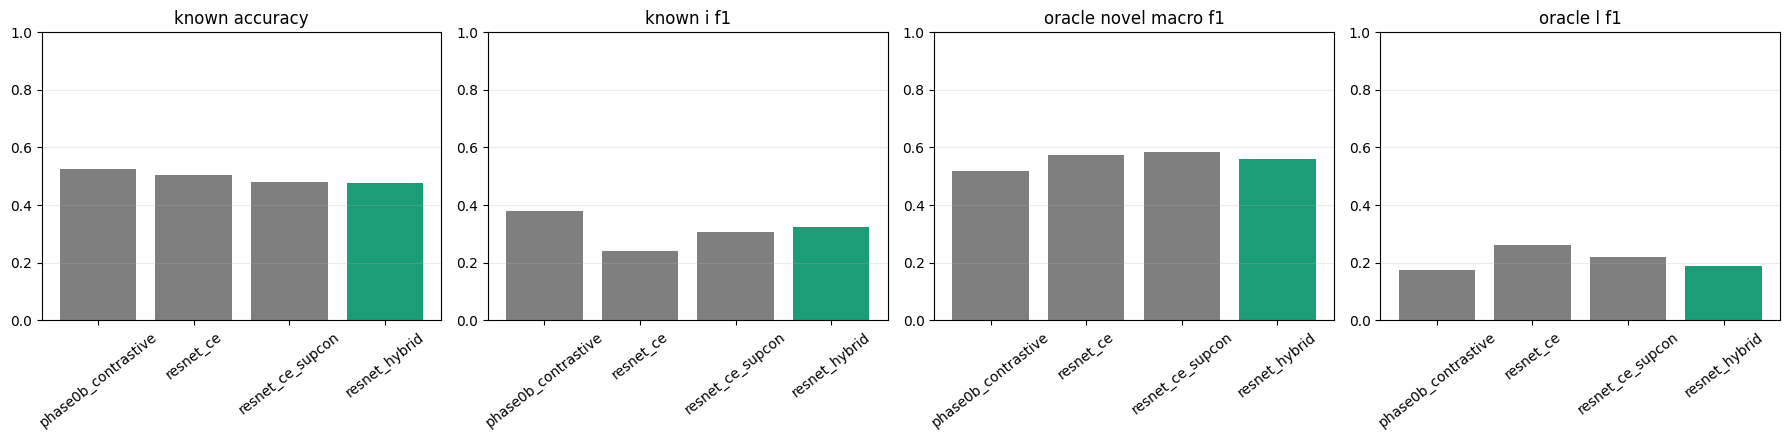

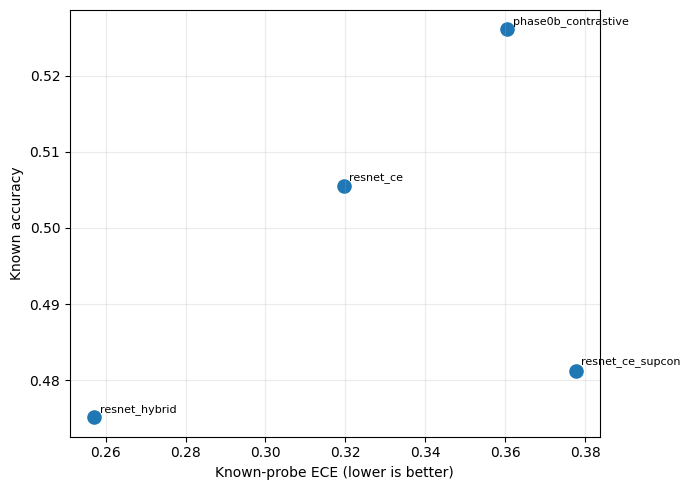

213

In [9]:
metrics=['known_accuracy','known_i_f1','oracle_novel_macro_f1','oracle_l_f1']
fig,axes=plt.subplots(1,4,figsize=(18,4.5))
for ax,metric in zip(axes,metrics):
    ax.bar(results.model,results[metric],color=['#7f7f7f' if x!='resnet_hybrid' else '#1b9e77' for x in results.model])
    ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=38);ax.grid(axis='y',alpha=.25);ax.set_ylim(0,1)
fig.tight_layout();fig.savefig(OUT/'phase2a_encoder_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(results.known_ece,results.known_accuracy,s=90)
for row in results.itertuples():ax.annotate(row.model,(row.known_ece,row.known_accuracy),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('Known-probe ECE (lower is better)');ax.set_ylabel('Known accuracy');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2a_accuracy_calibration.png',dpi=180,bbox_inches='tight');plt.show()

selected_row=results[results.model==SELECTED_ENCODER].iloc[0]
if SELECTED_ENCODER=='phase0b_contrastive':
    selected_checkpoint={'source':'phase0b','path':str(BASELINE_MODEL),'selection':selection.set_index('model').loc[SELECTED_ENCODER].to_dict()}
else:
    source=torch.load(OUT/f'{SELECTED_ENCODER}.pt',map_location='cpu',weights_only=False)
    selected_checkpoint={**source,'selection':selection.set_index('model').loc[SELECTED_ENCODER].to_dict()}
    torch.save(selected_checkpoint,OUT/'phase2a_selected_encoder.pt')
(OUT/'phase2a_selected_encoder.json').write_text(json.dumps(
    {'selected_encoder':SELECTED_ENCODER,'development_selection':selection.set_index('model').loc[SELECTED_ENCODER].to_dict()},indent=2))


## Phase 2A decision gates

The development-selected encoder must improve final known recognition, repair activity I, support the oracle novel vocabulary, repair activity L, and improve calibration relative to the Phase Zero-B baseline. Evaluation results cannot change which encoder was selected.


In [10]:
selected=results[results.model==SELECTED_ENCODER].iloc[0]
baseline_row=results[results.model=='phase0b_contrastive'].iloc[0]
gates={
 'G1_no_evaluation_subject_in_training_or_selection':not bool(set(CFG.evaluation_subjects)&(
    set(CFG.encoder_train_subjects)|set(CFG.encoder_selection_subjects)|set(CFG.unlabeled_integration_subjects))),
 'G2_selected_only_on_development':bool(selected.selected_on_development),
 'G3_known_accuracy':bool(selected.known_accuracy>=CFG.known_accuracy_gate and selected.known_accuracy>baseline_row.known_accuracy),
 'G4_known_I_f1':bool(selected.known_i_f1>=CFG.known_i_f1_gate),
 'G5_oracle_novel_macro_f1':bool(selected.oracle_novel_macro_f1>=CFG.oracle_novel_f1_gate),
 'G6_novel_L_f1':bool(selected.oracle_l_f1>=CFG.novel_l_f1_gate),
 'G7_known_calibration_improves':bool(selected.known_ece<baseline_row.known_ece),
 'G8_artifacts_complete':bool(len(selection)==len(MODEL_NAMES) and len(results)==len(MODEL_NAMES) and len(per_class)>0)
}
decision={'phase':'Phase 2A','selected_encoder':SELECTED_ENCODER,
          'selected_results':{k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else v)
                              for k,v in selected.to_dict().items()},
          'baseline_results':{k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else v)
                              for k,v in baseline_row.to_dict().items()},
          'gates':gates,'rerun_phase1c_with_selected_encoder':bool(all(gates.values())),
          'label_policy':'Only development known labels trained/selected encoders; integration streams were unlabeled; evaluation labels were final diagnostics only.',
          'config':asdict(CFG)}
(OUT/'phase2a_decision.json').write_text(json.dumps(decision,indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 2A",
  "selected_encoder": "resnet_ce_supcon",
  "selected_results": {
    "model": "resnet_ce_supcon",
    "known_accuracy": 0.4812121212121212,
    "known_macro_f1": 0.5010714906597107,
    "known_i_f1": 0.3053763440860215,
    "known_ece": 0.3776017720781704,
    "oracle_known_accuracy": 0.31272727272727274,
    "oracle_novel_macro_f1": 0.5838894225477864,
    "oracle_l_f1": 0.2198581560283688,
    "oracle_combined_macro_f1": 0.4346425162375401,
    "oracle_ece": 0.29359990329919833,
    "selected_on_development": true
  },
  "baseline_results": {
    "model": "phase0b_contrastive",
    "known_accuracy": 0.526060606060606,
    "known_macro_f1": 0.5192114155679227,
    "known_i_f1": 0.3780487804878049,
    "known_ece": 0.3604702557071097,
    "oracle_known_accuracy": 0.37212121212121213,
    "oracle_novel_macro_f1": 0.519697526920067,
    "oracle_l_f1": 0.17424242424242425,
    "oracle_combined_macro_f1": 0.4077498117022902,
    "oracle_ece": 0.3850990876296902,
 

In [11]:
report=f"""# FedVocabHAR Phase 2A Decision Report

## Decision

**Selected encoder:** {SELECTED_ENCODER}

**Rerun Phase 1C with selected encoder:** {decision['rerun_phase1c_with_selected_encoder']}

## Selected frozen-encoder diagnostics

- Known accuracy: {selected.known_accuracy:.4f}
- Known activity I F1: {selected.known_i_f1:.4f}
- Oracle novel macro-F1: {selected.oracle_novel_macro_f1:.4f}
- Novel activity L F1: {selected.oracle_l_f1:.4f}
- Known calibration error: {selected.known_ece:.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+="""

Encoder selection used only known-activity development labels. Integration-client activity labels and all evaluation-client labels were excluded from encoder training and selection.
"""
(OUT/'FedVocabHAR_Phase2A_Decision_Report.md').write_text(report)
print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 2A Decision Report

## Decision

**Selected encoder:** resnet_ce_supcon

**Rerun Phase 1C with selected encoder:** False

## Selected frozen-encoder diagnostics

- Known accuracy: 0.4812
- Known activity I F1: 0.3054
- Oracle novel macro-F1: 0.5839
- Novel activity L F1: 0.2199
- Known calibration error: 0.3776

## Gates

- G1_no_evaluation_subject_in_training_or_selection: **True**
- G2_selected_only_on_development: **True**
- G3_known_accuracy: **False**
- G4_known_I_f1: **False**
- G5_oracle_novel_macro_f1: **False**
- G6_novel_L_f1: **False**
- G7_known_calibration_improves: **False**
- G8_artifacts_complete: **True**


Encoder selection used only known-activity development labels. Integration-client activity labels and all evaluation-client labels were excluded from encoder training and selection.

saved outputs to /content/drive/MyDrive/FedVocabHAR/artifacts/phase2a


## Interpretation

- If every gate passes, freeze the selected encoder and rerun the unchanged Phase 1C admission and replay experiment.
- If known recognition improves but L remains below its gate, inspect the oracle confusion matrix before changing integration.
- If no development-selected encoder improves both known recognition and oracle novel separability, the WISDM single-sensor formulation is insufficient for this paper direction and the sensing setup or research claim must change.
